# Features: one real cell-week, then the training population

The example is **Santa Cruz cell `r1445c2432`, issue 2024-09-02 at 00:00 UTC**.
It has substantial antecedent activity and a complete target, so the distinction between history
and the following seven days is visible. It was chosen descriptively by maximizing the preceding
28-day count among positive cells with complete 28-day observation history at this issue, with
cell-ID tie breaking. It is not a model-selection example.

Strict history uses only primary national detections with acquisition time strictly before issue.
Climatology is a cross-fitted training-label statistic with the explicit LOYO exception below.
All reads are local; the pipeline functions run in memory without rebuilding the panel.

In [1]:
import gc
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display

from bolivia_fire.config import REPO_ROOT
from bolivia_fire.detections import selection_mask
from bolivia_fire.features import DailyHistory, TrainingClimatology, week_index
from bolivia_fire.figures import COLORS, chart_style
from bolivia_fire.labels import explain_label, labels_for_issue
from bolivia_fire.models.retrospective import COMPLETENESS
from bolivia_fire.panel import _prior_cells, _read_interval

root = REPO_ROOT
issue = pd.Timestamp("2024-09-02")
cell_id = "r1445c2432"
cells = pd.read_parquet(root / "datasets/processed/cells.parquet")
schema = yaml.safe_load((root / "datasets/schemas/panel.yaml").read_text(encoding="utf-8"))
experiments = yaml.safe_load((root / "configs/experiments.yaml").read_text(encoding="utf-8"))
bundle = json.loads((root / "datasets/interim/detection_bundle.json").read_text(encoding="utf-8"))
bundle_dir = root / "datasets/interim" / bundle["directory"]
source = bundle_dir / "detections.parquet"
days = pd.read_parquet(bundle_dir / "acquisition_days.parquet")
panel_issue = pd.read_parquet(
    root / "datasets/processed/panel/year=2024/part.parquet", filters=[("issue_date", "==", issue)]
)
example = panel_issue.set_index("cell_id").loc[cell_id]
display(
    example[
        [
            "issue_date",
            "department",
            "count_last_28d",
            "n_primary",
            "y_primary",
            "window_obs_complete_28d",
            "target_complete",
        ]
    ].to_frame("Recorded example")
)

,Recorded example
issue_date,2024-09-02 00:00:00
department,Santa Cruz
count_last_28d,574.0
n_primary,12
y_primary,1
window_obs_complete_28d,True
target_complete,True


## Strict definitions

This table follows `datasets/schemas/panel.yaml` and the frozen strict column list in
`configs/experiments.yaml`. All count windows are half-open UTC intervals. Neighborhoods include
the center cell; ineligible grid cells contribute zero. National history includes every covered
primary point, including points in boundary-only ineligible cells. FRP is a sum of detection-level
megawatts, not an energy total. Values below come from the recorded example row.

In [2]:
def feature_definition(name: str) -> str:
    specification = schema["columns"][name]
    if "formula" in specification:
        return specification["formula"] + "; w = min((day_of_year - 1) // 7, 51)"
    if name.startswith("count_last_"):
        length = name.removeprefix("count_last_").removesuffix("d")
        return f"Primary national detections in this cell in [issue - {length}d, issue)"
    if name.startswith("neighborhood_"):
        width, length = name.removeprefix("neighborhood_").split("_last_")
        return f"Primary counts in centered {width} cells over [issue - {length}, issue)"
    if name.startswith("national_last_"):
        length = name.removeprefix("national_last_")
        return f"All covered primary national points in [issue - {length}, issue)"
    definitions = {
        "any_last_7d": "count_last_7d > 0",
        "days_since_last": "UTC calendar days since latest prior detection; cap 730; 730 if unseen",
        "no_prior_detection": specification.get("description", ""),
        "frp_sum_28d": "Sum of primary detection FRP in this cell in [issue - 28d, issue), MW",
        "same_week_last_year": specification.get("window", ""),
        "train_climatology_cell": "Cell-week train-label mean; offsets -2..2; LOYO",
        "train_climatology_dept": "Department mean; equal cell-week weights; offsets -2..2; LOYO",
        "window_obs_complete_365d": specification.get("description", ""),
    }
    return definitions[name]


names = experiments["strict_features"]
definitions = pd.DataFrame(
    [
        {
            "Feature": name,
            "dtype": schema["columns"][name]["dtype"],
            "Definition": feature_definition(name),
            "Example": example[name],
        }
        for name in names
    ]
).set_index("Feature")
display(
    definitions.style.set_properties(
        subset=["Definition"],
        **{
            "white-space": "normal",
            "max-width": "520px",
            "text-align": "left",
        },
    )
)

,dtype,Definition,Example
Feature,,,
count_last_7d,float32,"Primary national detections in this cell in [issue - 7d, issue)",534.000000
count_last_14d,float32,"Primary national detections in this cell in [issue - 14d, issue)",574.000000
count_last_28d,float32,"Primary national detections in this cell in [issue - 28d, issue)",574.000000
count_last_91d,float32,"Primary national detections in this cell in [issue - 91d, issue)",574.000000
count_last_365d,float32,"Primary national detections in this cell in [issue - 365d, issue)",574.000000
any_last_7d,bool,count_last_7d > 0,True
days_since_last,float32,UTC calendar days since latest prior detection; cap 730; 730 if unseen,1.000000
no_prior_detection,bool,no primary national detection in available prior history,False
frp_sum_28d,float32,"Sum of primary detection FRP in this cell in [issue - 28d, issue), MW",3479.449951


## Reconstruct history from detections

`DailyHistory` receives the complete national cell grid, two years of detections, observation
flags and the set of cells seen before that range. The extra earlier year preserves recency
up to its 730-day cap. Future detections are intentionally present in the input: time filtering
belongs inside the pipeline. The assertion compares every derived history column for every cell
against the saved panel at this issue.

In [3]:
start, end = issue - pd.Timedelta(days=730), issue + pd.Timedelta(days=7)
detections = _read_interval(source, start, end)
prior_cells = _prior_cells(source, start)
history = DailyHistory(cells, detections, days, start, end, prior_cells)
built = history.features(issue).set_index("cell_id")
recorded = panel_issue.set_index("cell_id").reindex(built.index)
for name in built.columns:
    np.testing.assert_allclose(
        built[name].astype(float),
        recorded[name].astype(float),
        rtol=1e-6,
        atol=1e-5,
        equal_nan=True,
    )
display(built.loc[cell_id].to_frame("Reconstructed history"))
print(f"Verified {len(built):,} cells and {len(built.columns)} history columns against the panel.")
del history
_ = gc.collect()

selected = detections[detections.in_bolivia & selection_mask(detections)]
local = selected[selected.cell_id.eq(cell_id)]
window_checks = []
for length in (7, 14, 28, 91, 365):
    rows = local[
        (local.acq_datetime >= (issue - pd.Timedelta(days=length)).tz_localize("UTC"))
        & (local.acq_datetime < issue.tz_localize("UTC"))
    ]
    count = len(rows)
    assert count == built.loc[cell_id, f"count_last_{length}d"]
    window_checks.append(
        {
            "Window (days)": length,
            "Start inclusive": issue - pd.Timedelta(days=length),
            "End exclusive": issue,
            "Detection count": count,
        }
    )
display(pd.DataFrame(window_checks))
label = labels_for_issue(cells, detections, days, issue).set_index("cell_id").loc[cell_id]
assert label.y_primary == example.y_primary
assert label.n_primary == example.n_primary
display(
    explain_label(detections, cell_id, issue)[["acq_datetime", "confidence", "frp"]]
    .sort_values("acq_datetime")
    .reset_index(drop=True)
)

,Reconstructed history
count_last_7d,534.0
count_last_14d,574.0
count_last_28d,574.0
count_last_91d,574.0
count_last_365d,574.0
any_last_7d,True
days_since_last,1.0
no_prior_detection,False
frp_sum_28d,3479.449951
same_week_last_year,0.0


Verified 37,146 cells and 22 history columns against the panel.


,Window (days),Start inclusive,End exclusive,Detection count
0,7,2024-08-26,2024-09-02,534
1,14,2024-08-19,2024-09-02,574
2,28,2024-08-05,2024-09-02,574
3,91,2024-06-03,2024-09-02,574
4,365,2023-09-03,2024-09-02,574


,acq_datetime,confidence,frp
0,2024-09-02 04:36:00+00:00,n,2.10
1,2024-09-02 04:36:00+00:00,n,2.10
2,2024-09-02 04:36:00+00:00,n,2.74
3,2024-09-02 04:36:00+00:00,n,2.74
4,2024-09-02 17:07:00+00:00,n,29.48
5,2024-09-03 04:17:00+00:00,n,3.30
6,2024-09-03 04:17:00+00:00,n,1.43
7,2024-09-03 05:57:00+00:00,n,1.68
8,2024-09-03 05:57:00+00:00,n,1.68
9,2024-09-03 05:58:00+00:00,n,2.37


## No look-ahead: perturb the issue boundary and future

The following **synthetic perturbation** duplicates real target detections, moves their times
to the issue instant and three days later, and changes their FRP. The full history feature frame
must remain exactly equal, including national counts and neighborhoods. Labels are deliberately
not compared: their target starts at issue and can change under this perturbation.

In [4]:
future = detections[detections.acq_datetime >= issue.tz_localize("UTC")].head(50).copy()
assert len(future) > 0
future["acq_datetime"] = issue.tz_localize("UTC")
future["frp"] = np.full(len(future), 1_000_000, dtype=detections.frp.dtype)
later = future.copy()
later["acq_datetime"] += pd.Timedelta(days=3)
perturbed = pd.concat([detections, future, later], ignore_index=True)
assert perturbed.frp.dtype == detections.frp.dtype
changed_history = DailyHistory(cells, perturbed, days, start, end, prior_cells)
changed = changed_history.features(issue).set_index("cell_id")
pd.testing.assert_frame_equal(built, changed, check_exact=True)
print(f"Exact invariance after adding {len(future) + len(later)} synthetic future detections.")
del changed_history, changed, perturbed, future, later, detections, selected, local
_ = gc.collect()

Exact invariance after adding 100 synthetic future detections.


## Leave-one-year-out training climatology

`TrainingClimatology` pools complete, non-purged training labels outside held-out blocks over
circular week offsets -2 through 2. For a training query it excludes that calendar year; this
explicit protocol exception can use other training years later than the query. Later queries
use all 2013-2020 training years. Validation, test and held-out labels never enter either mean.
The department estimate gives equal weight to each eligible cell-week, rather than each cell.

We feed the saved training labels through the same estimator, then verify the real 2024 cell
and department means. A training issue with the same calendar week index is checked separately
against its saved LOYO value and against a direct pooled-label oracle.

In [5]:
train_years = range(2013, 2021)
climatology = TrainingClimatology(cells, train_years)
training_example = None
for year in train_years:
    training = pd.read_parquet(
        root / f"datasets/processed/panel/year={year}/part.parquet",
        columns=["cell_id", "issue_date", "partition", "y_primary", "train_climatology_cell"],
        filters=[("partition", "==", "train")],
    )
    for training_issue, labels in training.groupby("issue_date", sort=False):
        climatology.add(pd.Timestamp(training_issue), labels)
        if year == 2019 and week_index(pd.Timestamp(training_issue)) == week_index(issue):
            training_example = labels.loc[labels.cell_id.eq(cell_id)].iloc[0].copy()
    del training
position = cells.index[cells.cell_id.eq(cell_id)][0]
for name, value in {
    "train_climatology_cell": climatology.predict(issue)[position],
    "train_climatology_dept": climatology.predict_department(issue)[position],
}.items():
    np.testing.assert_allclose(value, example[name], rtol=1e-6)
assert training_example is not None
training_issue = pd.Timestamp(training_example.issue_date)
weeks = [(week_index(training_issue) + offset) % 52 for offset in range(-2, 3)]
contributions = pd.DataFrame(
    {
        "Year": list(train_years),
        "Positive cell-weeks": [climatology.sums[i, weeks, position].sum() for i in range(8)],
        "Complete cell-weeks": [climatology.counts[i, weeks, position].sum() for i in range(8)],
    }
)
contributions["Used for training query"] = contributions.Year.ne(training_issue.year)
kept = contributions[contributions["Used for training query"]]
oracle = kept["Positive cell-weeks"].sum() / kept["Complete cell-weeks"].sum()
loyo = climatology.predict(training_issue)[position]
np.testing.assert_allclose(loyo, oracle, rtol=1e-6)
np.testing.assert_allclose(loyo, training_example.train_climatology_cell, rtol=1e-6)
display(contributions)
display(
    pd.DataFrame(
        [
            {"Query": training_issue, "Reference": "Other train years (LOYO)", "Cell mean": loyo},
            {
                "Query": issue,
                "Reference": "All train years",
                "Cell mean": example.train_climatology_cell,
            },
        ]
    )
)
del climatology
_ = gc.collect()

,Year,Positive cell-weeks,Complete cell-weeks,Used for training query
0,2013,0,5,True
1,2014,0,5,True
2,2015,0,5,True
3,2016,0,5,True
4,2017,0,5,True
5,2018,0,5,True
6,2019,0,5,False
7,2020,1,5,True


,Query,Reference,Cell mean
0,2019-09-09,Other train years (LOYO),0.028571
1,2024-09-02,All train years,0.025000


## Positive and negative training cell-weeks

A deterministic hash sample of at most 50,000 eligible training rows is used only to describe
feature distributions. The filter keeps non-held-out cells with labels and complete 28-day
observation history. Sampling uses cell and issue together across all eight training years.
The empirical CDFs include zeros; count and FRP axes use log1p. These differences are descriptive,
not causal effects or out-of-sample performance.

y_primary                                 0           1
count_last_7d            median    0.000000    0.000000
                         mean      0.063672    1.726316
count_last_28d           median    0.000000    0.000000
                         mean      0.294167    4.923684
count_last_365d          median    0.000000    8.000000
                         mean      4.914818   20.635965
days_since_last          median  730.000000   31.500000
                         mean    508.439911  159.923691
frp_sum_28d              median    0.000000    0.000000
                         mean      3.026561   48.747387
neighborhood_3x3_last_7d median    0.000000    1.000000
                         mean      0.674785   11.655263
train_climatology_cell   median    0.000000    0.114286
                         mean      0.018308    0.147279
train_climatology_dept   median    0.008550    0.052671
                         mean      0.020883    0.051126

Sample class counts: {0: 48860, 1: 1140}


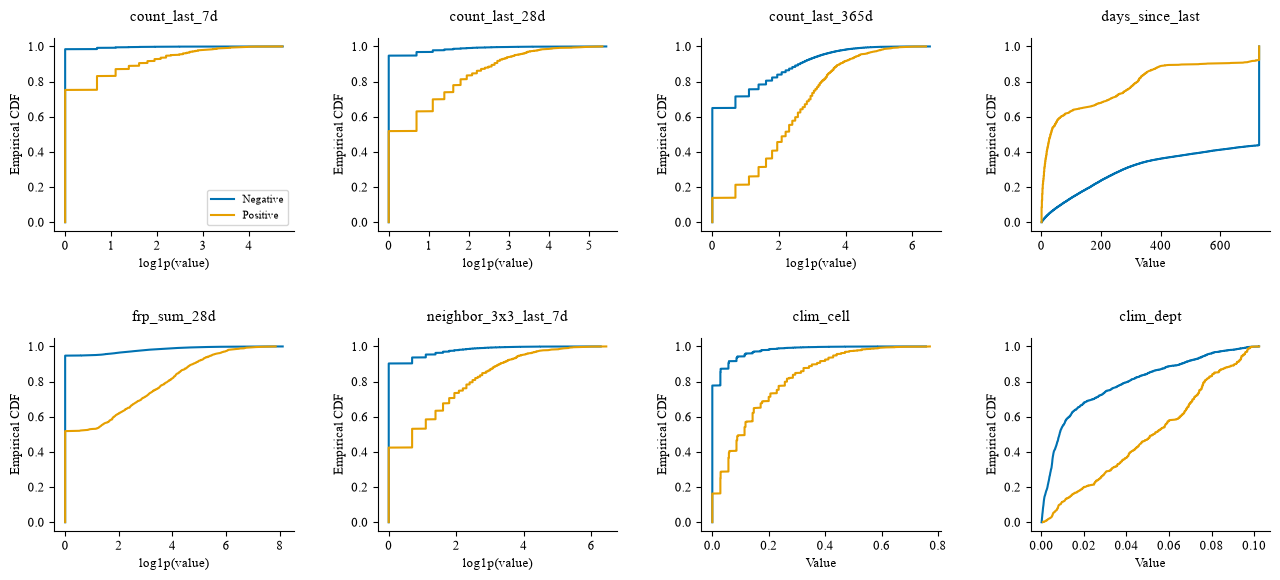

Chart font: Times New Roman


In [6]:
keys = [
    "count_last_7d",
    "count_last_28d",
    "count_last_365d",
    "days_since_last",
    "frp_sum_28d",
    "neighborhood_3x3_last_7d",
    "train_climatology_cell",
    "train_climatology_dept",
]
train_files = [
    (root / f"datasets/processed/panel/year={year}/part.parquet").as_posix() for year in train_years
]
connection = duckdb.connect(config={"memory_limit": "512MB", "threads": 2})
query = (
    "SELECT y_primary, " + ", ".join(keys) + " FROM read_parquet(?, hive_partitioning=false) "
    "WHERE partition = 'train' AND NOT geo_holdout AND y_primary IS NOT NULL "
    "AND window_obs_complete_28d ORDER BY hash(cell_id, issue_date) LIMIT 50000"
)
sample = connection.execute(query, [train_files]).df()
display(sample.groupby("y_primary")[keys].agg(["median", "mean"]).T)
print("Sample class counts:", sample.y_primary.value_counts().sort_index().to_dict())
with chart_style() as font:
    figure, axes = plt.subplots(2, 4, figsize=(13, 6), layout="constrained")
    for ax, name in zip(axes.flat, keys, strict=True):
        for value, color, label_text in [(0, COLORS[0], "Negative"), (1, COLORS[1], "Positive")]:
            values = sample.loc[sample.y_primary.eq(value), name].dropna().to_numpy()
            values = np.sort(
                values if "climatology" in name or name == "days_since_last" else np.log1p(values)
            )
            ax.plot(
                values, np.arange(1, len(values) + 1) / len(values), color=color, label=label_text
            )
        title = name.replace("neighborhood_", "neighbor_").replace("train_climatology_", "clim_")
        ax.set_title(title)
        ax.set_xlabel(
            "Value" if "climatology" in name or name == "days_since_last" else "log1p(value)"
        )
        ax.set_ylabel("Empirical CDF")
    axes.flat[0].legend()
    plt.show()
print("Chart font:", font)

## Retrospective CHIRPS rainfall and completeness

The five frozen rainfall features are antecedent sums over 7, 30 and 90 days (mm), dry days
below 1 mm during the preceding 30 days, and the 90-day sum divided by the mean corresponding
sum in training reference years. The ratio is not a z-score. The reference excludes the query
year for training rows, with February 29 mapped to February 28 when needed.

These are retrospective CHIRPS v3 values: historical vintages were not verified as available at
issue time. A missing day makes its window incomplete and its feature null; rainfall is never
zero-filled. Model eligibility also requires all associated completeness flags. The table scans
the recorded rainfall features without extracting or downloading rasters. MapBiomas is absent
from the frozen retrospective model inputs.

In [7]:
rain_files = sorted(
    (root / "datasets/processed/covariates/chirps_features").glob("year=*/part.parquet")
)
rain_names = experiments["retrospective_features"]
rows = []
for path in rain_files:
    rain = pd.read_parquet(path)
    row = {"Year": int(path.parent.name.removeprefix("year=")), "Cell-weeks": len(rain)}
    for name in rain_names:
        valid = np.isfinite(rain[name].to_numpy())
        for flag in COMPLETENESS[name]:
            valid &= rain[flag].fillna(False).to_numpy(dtype=bool)
        row[name + " complete share"] = valid.mean()
    rows.append(row)
    if row["Year"] == issue.year:
        rain_example = rain.loc[rain.cell_id.eq(cell_id) & rain.issue_date.eq(issue)].iloc[0]
    del rain
display(pd.DataFrame(rows).set_index("Year"))
display(
    pd.DataFrame(
        [
            {
                "Feature": name,
                "Example": rain_example[name],
                "Required flags": ", ".join(COMPLETENESS[name]),
                "Complete": all(bool(rain_example[flag]) for flag in COMPLETENESS[name]),
            }
            for name in rain_names
        ]
    ).set_index("Feature")
)
connection.close()
display(Markdown("Continue with [validation and modeling](03_modeling.ipynb)."))

,Cell-weeks,rain_sum_7d complete share,rain_sum_30d complete share,rain_sum_90d complete share,dry_days_30d complete share,rain_anomaly_90d complete share
Year,,,,,,
2013,1931592,1.0,1.0,1.0,1.0,1.0
2014,1931592,1.0,1.0,1.0,1.0,1.0
2015,1931592,1.0,1.0,1.0,1.0,1.0
2016,1931592,1.0,1.0,1.0,1.0,1.0
2017,1931592,1.0,1.0,1.0,1.0,1.0
2018,1968738,1.0,1.0,1.0,1.0,1.0
2019,1931592,1.0,1.0,1.0,1.0,1.0
2020,1931592,1.0,1.0,1.0,1.0,1.0
2021,1931592,1.0,1.0,1.0,1.0,1.0


,Example,Required flags,Complete
Feature,,,
rain_sum_7d,0.110160,rain_complete_7d,True
rain_sum_30d,12.970951,rain_complete_30d,True
rain_sum_90d,17.741211,rain_complete_90d,True
dry_days_30d,29.000000,rain_complete_30d,True
rain_anomaly_90d,0.240464,"rain_complete_90d, rain_climatology_complete",True


Continue with [validation and modeling](03_modeling.ipynb).